<a href="https://colab.research.google.com/github/ReNZzyi/IT-and-Programming/blob/main/%D0%9B%D0%B0%D0%B1%D0%BE%D1%80%D0%B0%D1%82%D0%BE%D1%80%D0%BD%D0%B0%D1%8F_%D1%80%D0%B0%D0%B1%D0%BE%D1%82%D0%B0_13.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторная работа 13. Основы обучаемых алгоритмов

ФИО студента: **Петров Данила Максимович**

Группа студента: **ИНБ-б-о-26-2**

Вариант: **14**

## Задание

В файле `pr13_14.txt` (**вариант 14**) содержатся точки некоторого распределения. Необходимо:
* выполнить визуализацию данных с использованием библиотеки matplotlib;
* обучить модель регрессии и найти значения её параметров;
* визуализировать, что модель хорошо описывает эмпирические данные;
* провести эксперименты со скоростью обучения и начальными значениями параметров и определить их влияние на процесс обучения.

## Решение

Подключаем библиотеки

In [1]:
import numpy as np
from matplotlib import pyplot as plt
import seaborn as sns

Получаем данные

In [ ]:
!wget https://raw.githubusercontent.com/enikolaev/IT-and-Programming/refs/heads/main/data/pract13/pr13_14.txt

Данные из файла конвертируем в два массива: `X` (координаты X точек) и `y` (координаты Y точек).

В отличие от учебного примера, используем одномерные массивы. При двумерных массивах-столбцах градиент по `k` получается матрицей 1×1, и `float(k - alpha * gk)` вызывает предупреждение `DeprecationWarning` в NumPy ≥ 1.25. С одномерными массивами все величины остаются обычными числами.

In [3]:
X, y = [], []
with open('pr13_14.txt') as fi:
    for line in fi:
        s = line.strip().split()
        X.append(float(s[0]))
        y.append(float(s[1]))
X = np.array(X)
y = np.array(y)

print('Количество точек:', y.shape[0])
print(f'X: от {X.min():.2f} до {X.max():.2f}')
print(f'y: от {y.min():.2f} до {y.max():.2f}')

Количество точек: 500
X: от -2.89 до 2.68
y: от -424.08 до -289.88


Проанализируем полученное распределение:

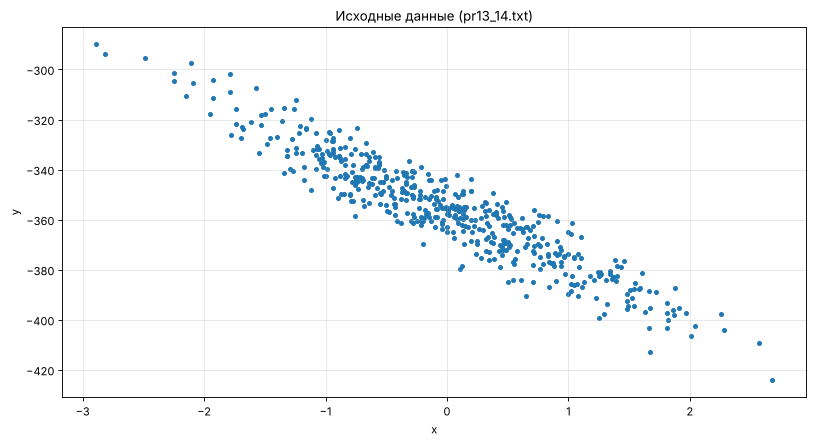

In [4]:
plt.figure(figsize=(12, 6))
plt.scatter(X, y, s=12)
plt.xlabel('x')
plt.ylabel('y')
plt.title('Исходные данные (pr13_14.txt)')
plt.grid(alpha=0.3)
plt.show()

На основе визуального анализа делаем вывод: точки вытянуты вдоль убывающей прямой с равномерным разбросом. При росте x на 1 значение y уменьшается примерно на 20, а при x = 0 значение y около −356. Поэтому аппроксимируем распределение прямой $y = k \cdot x + b$. Обучение модели сводится к подбору коэффициентов $k$ и $b$.

**Функция ошибки** - среднеквадратичное отклонение (MSE):
$$MSE(k, b) = \frac{1}{n}\sum_{i=1}^{n}\left(k x_i + b - y_i\right)^2$$

**Градиенты** (частные производные MSE по параметрам):
$$\frac{\partial MSE}{\partial k} = \frac{2}{n}\sum_{i=1}^{n}(k x_i + b - y_i)\,x_i, \qquad
\frac{\partial MSE}{\partial b} = \frac{2}{n}\sum_{i=1}^{n}(k x_i + b - y_i)$$

**Градиентный спуск** на каждой итерации сдвигает параметры против градиента со скоростью (темпом) обучения $\alpha$:
$$k \leftarrow k - \alpha \frac{\partial MSE}{\partial k}, \qquad b \leftarrow b - \alpha \frac{\partial MSE}{\partial b}$$

In [5]:
def mse(k, b):
    return np.mean((k * X + b - y) ** 2)


def train(k0=0.0, b0=0.0, alpha=0.1, epochs=100):
    k, b = k0, b0
    history = [(k, b, mse(k, b))]
    for _ in range(epochs):
        error = k * X + b - y
        grad_k = 2 * np.mean(error * X)
        grad_b = 2 * np.mean(error)
        k -= alpha * grad_k
        b -= alpha * grad_b
        current = mse(k, b)
        history.append((k, b, current))
        if not np.isfinite(current) or current > 1e12:
            break
    return k, b, np.array(history)

### Обучение модели

Начальные значения $k = 0$, $b = 0$, скорость обучения $\alpha = 0.1$, 100 итераций. Посмотрим, как прямая приближается к данным на разных итерациях:

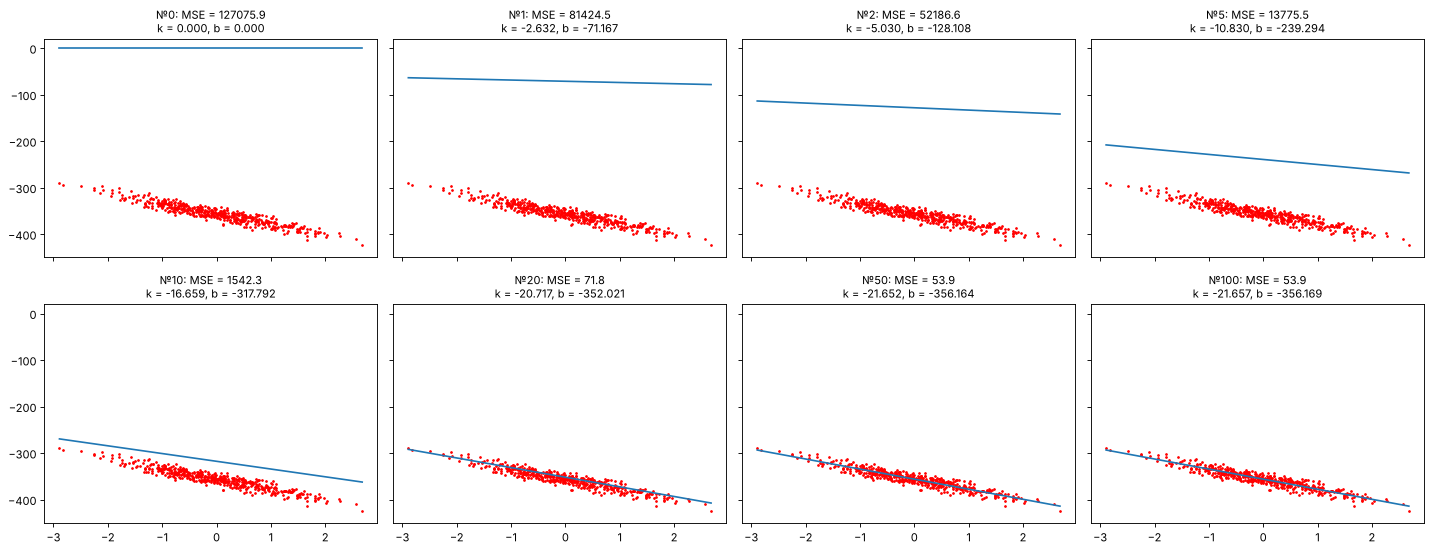

In [6]:
k, b, history = train(k0=0.0, b0=0.0, alpha=0.1, epochs=100)

steps = [0, 1, 2, 5, 10, 20, 50, 100]
xmin, xmax = X.min(), X.max()
fig, axes = plt.subplots(2, 4, figsize=(18, 7), sharex=True, sharey=True)
for ax, step in zip(axes.flat, steps):
    k_i, b_i, mse_i = history[step]
    ax.scatter(X, y, color='red', s=2)
    ax.plot([xmin, xmax], [k_i * xmin + b_i, k_i * xmax + b_i])
    ax.set_title(f'№{step}: MSE = {mse_i:.1f}\nk = {k_i:.3f}, b = {b_i:.3f}', fontsize=10)
axes[0, 0].set_ylim(-450, 20)
plt.tight_layout()
plt.show()

На первых итерациях прямая быстро «опускается» к облаку точек (больше всего меняется $b$), затем поворачивается и уточняется. Проверяем полученную модель:

MSE = 53.9495, k = -21.656718, b = -356.169086


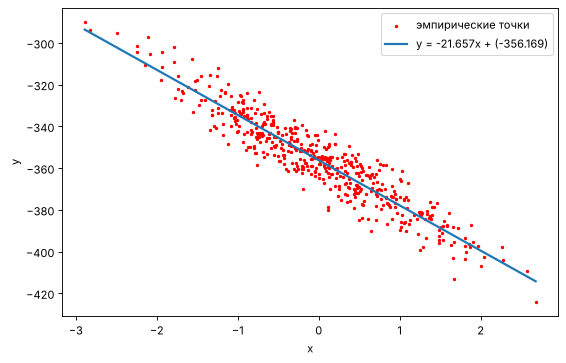

In [7]:
print(f'MSE = {mse(k, b):.4f}, k = {k:10f}, b = {b:10f}')

plt.figure(figsize=(8, 5))
plt.scatter(X, y, color='red', s=4, label='эмпирические точки')
plt.plot([xmin, xmax], [k * xmin + b, k * xmax + b], lw=2,
         label=f'y = {k:.3f}x + ({b:.3f})')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.show()

Сравним результат с аналитическим решением методом наименьших квадратов (`np.polyfit`), которое находит минимум MSE точно, без итераций:

In [8]:
k_exact, b_exact = np.polyfit(X, y, 1)
print(f'Градиентный спуск: k = {k:.4f}, b = {b:.4f}, MSE = {mse(k, b):.4f}')
print(f'np.polyfit (МНК):  k = {k_exact:.4f}, b = {b_exact:.4f}, MSE = {mse(k_exact, b_exact):.4f}')
print('Совпадение до 1e-3:', np.allclose([k, b], [k_exact, b_exact], atol=1e-3))
MSE_OPT = mse(k_exact, b_exact)

Градиентный спуск: k = -21.6567, b = -356.1691, MSE = 53.9495
np.polyfit (МНК):  k = -21.6567, b = -356.1691, MSE = 53.9495
Совпадение до 1e-3: True


Изменение ошибки в процессе обучения (логарифмическая шкала):

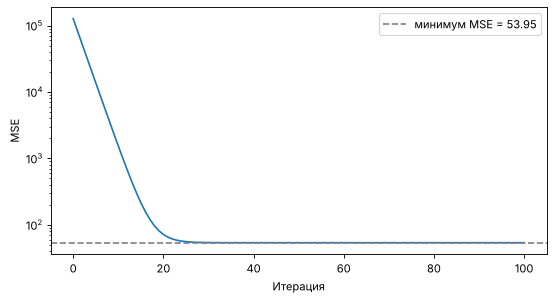

In [9]:
plt.figure(figsize=(8, 4))
plt.plot(history[:, 2])
plt.axhline(MSE_OPT, color='gray', ls='--', label=f'минимум MSE = {MSE_OPT:.2f}')
plt.yscale('log')
plt.xlabel('Итерация')
plt.ylabel('MSE')
plt.legend()
plt.show()

Ошибка уменьшается с ~127 000 до ≈ 53.95 и выходит на минимум. Минимальная MSE не равна нулю: это дисперсия «шума» - разброса точек вокруг прямой ($\sqrt{53.95} \approx 7.3$).

### Эксперимент 1. Влияние скорости обучения

Обучим модель с одинаковыми начальными значениями $k = 0$, $b = 0$ и разными значениями $\alpha$. Будем считать, что модель сошлась, когда MSE отличается от минимума менее чем на 0.1 %.

In [10]:
def iterations_to_converge(history, tol=1e-3):
    reached = np.nonzero(history[:, 2] <= MSE_OPT * (1 + tol))[0]
    return int(reached[0]) if reached.size else None


alphas = [0.001, 0.01, 0.1, 0.5, 0.9, 1.05]
runs = {}
print(f"{'alpha':>6} | {'k':>10} | {'b':>10} | {'MSE':>12} | итераций до сходимости")
print('-' * 70)
for alpha in alphas:
    k_a, b_a, hist_a = train(alpha=alpha, epochs=200)
    runs[alpha] = hist_a
    n_conv = iterations_to_converge(hist_a)
    if not np.isfinite(hist_a[-1, 2]) or hist_a[-1, 2] > 1e6:
        status = f'расходится (остановлено на итерации {len(hist_a) - 1})'
    else:
        status = n_conv if n_conv is not None else 'не сошлось за 200'
    print(f'{alpha:>6} | {k_a:>10.3f} | {b_a:>10.3f} | {hist_a[-1, 2]:>12.4g} | {status}')

 alpha |          k |          b |          MSE | итераций до сходимости
----------------------------------------------------------------------
 0.001 |     -4.799 |   -117.420 |    5.718e+04 | не сошлось за 200
  0.01 |    -20.457 |   -349.857 |        94.79 | не сошлось за 200
   0.1 |    -21.657 |   -356.169 |        53.95 | 34
   0.5 |    -21.657 |   -356.169 |        53.95 | 3
   0.9 |    -21.657 |   -356.169 |        53.95 | 34
  1.05 | 113823.711 | -1026792.304 |    1.068e+12 | расходится (остановлено на итерации 81)


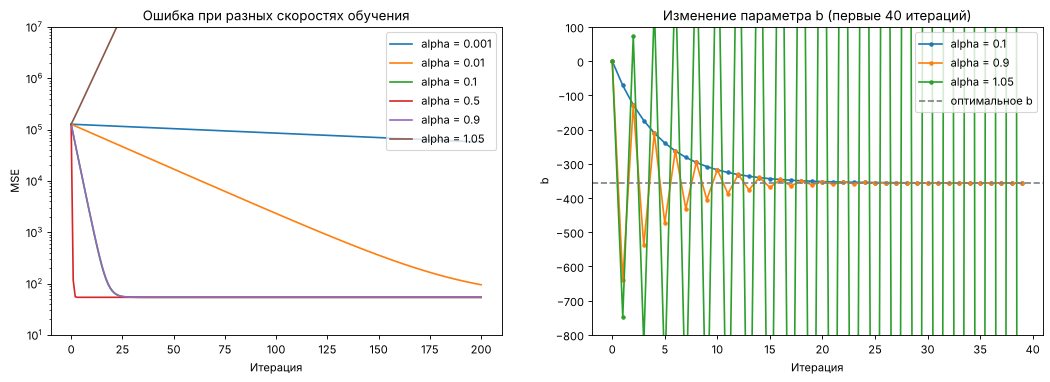

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for alpha, hist_a in runs.items():
    axes[0].plot(hist_a[:, 2], label=f'alpha = {alpha}')
axes[0].set_yscale('log')
axes[0].set_ylim(10, 1e7)
axes[0].set_xlabel('Итерация')
axes[0].set_ylabel('MSE')
axes[0].set_title('Ошибка при разных скоростях обучения')
axes[0].legend()

for alpha in [0.1, 0.9, 1.05]:
    axes[1].plot(runs[alpha][:40, 1], marker='.', label=f'alpha = {alpha}')
axes[1].axhline(b_exact, color='gray', ls='--', label='оптимальное b')
axes[1].set_ylim(-800, 100)
axes[1].set_xlabel('Итерация')
axes[1].set_ylabel('b')
axes[1].set_title('Изменение параметра b (первые 40 итераций)')
axes[1].legend()
plt.show()

**Выводы по эксперименту 1:**
* **слишком малая скорость** ($\alpha = 0.001$): шаги крошечные, за 200 итераций модель далека от оптимума - обучение очень медленное;
* $\alpha = 0.01$: за 200 итераций ошибка снизилась до ≈ 95, но минимума (≈ 53.95) модель не достигла - нужны ещё сотни итераций;
* **оптимальный диапазон** для этих данных - примерно $0.1 \ldots 0.5$: при $\alpha = 0.1$ модель сошлась за 34 итерации, при $\alpha = 0.5$ - всего за 3;
* $\alpha = 0.9$: параметры «перепрыгивают» минимум и колеблются вокруг него (график $b$ - пила), но амплитуда затухает, и модель сходится за 34 итерации - как и при $\alpha = 0.1$ (кривые ошибки этих двух запусков на левом графике совпадают). Это не случайность: за один шаг отклонение от минимума умножается на $|1 - \alpha\lambda|$, и для обоих значений $\alpha$ этот множитель ≈ 0.8, только при $\alpha = 0.9$ он отрицательный, отсюда колебания;
* **слишком большая скорость** ($\alpha = 1.05$): каждое перепрыгивание дальше предыдущего, ошибка растёт экспоненциально - обучение расходится.

Для MSE линейной модели граница устойчивости $\alpha < 2 / \lambda_{max}$, где $\lambda_{max}$ - наибольшее собственное число матрицы вторых производных (гессиана). Проверим это расчётом:

In [12]:
hessian = 2 * np.array([[np.mean(X ** 2), np.mean(X)],
                        [np.mean(X), 1.0]])
lambda_max = np.linalg.eigvalsh(hessian).max()
print(f'lambda_max = {lambda_max:.4f}, граница устойчивости alpha < {2 / lambda_max:.4f}')

lambda_max = 2.0034, граница устойчивости alpha < 0.9983


Расчёт подтверждает эксперимент: $\alpha = 0.9$ ещё ниже границы ≈ 0.998, а $\alpha = 1.05$ - уже выше.

### Эксперимент 2. Влияние начальных значений параметров

In [13]:
starts = [(0.0, 0.0), (100.0, 100.0), (-150.0, -600.0), (50.0, -500.0), (-21.0, -350.0)]
trajectories = {}
print(f"{'k0':>7} {'b0':>7} | {'MSE в начале':>12} | {'k':>9} | {'b':>9} | итераций до сходимости")
print('-' * 75)
for k0, b0 in starts:
    k_s, b_s, hist_s = train(k0=k0, b0=b0, alpha=0.1, epochs=150)
    trajectories[(k0, b0)] = hist_s
    print(f'{k0:>7} {b0:>7} | {hist_s[0, 2]:>12.1f} | {k_s:>9.3f} | {b_s:>9.3f} | '
          f'{iterations_to_converge(hist_s)}')

     k0      b0 | MSE в начале |         k |         b | итераций до сходимости
---------------------------------------------------------------------------
    0.0     0.0 |     127075.9 |   -21.657 |  -356.169 | 34
  100.0   100.0 |     219186.1 |   -21.657 |  -356.169 | 36
 -150.0  -600.0 |      72739.9 |   -21.657 |  -356.169 | 35
   50.0  -500.0 |      25487.2 |   -21.657 |  -356.169 | 31
  -21.0  -350.0 |         92.3 |   -21.657 |  -356.169 | 15


Изобразим траектории параметров на карте линий уровня функции ошибки $MSE(k, b)$:

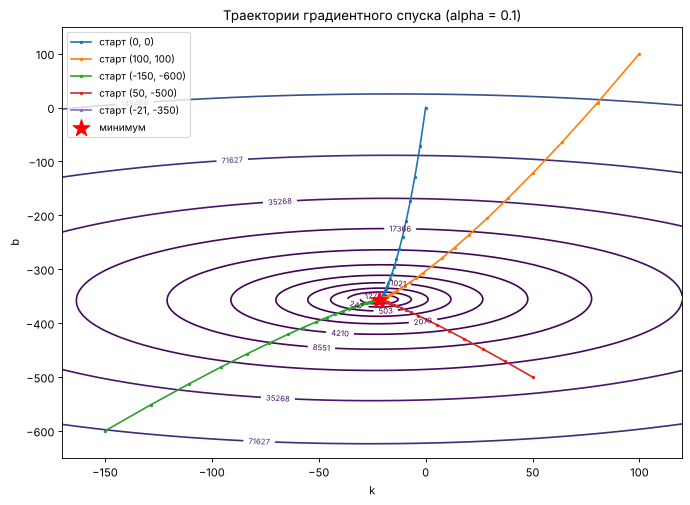

In [14]:
k_grid = np.linspace(-170, 120, 300)
b_grid = np.linspace(-650, 150, 300)
K, B = np.meshgrid(k_grid, b_grid)
Z = (K ** 2 * np.mean(X ** 2) + B ** 2 + np.mean(y ** 2)
     + 2 * K * B * np.mean(X) - 2 * K * np.mean(X * y) - 2 * B * np.mean(y))

plt.figure(figsize=(10, 7))
contours = plt.contour(K, B, Z, levels=np.geomspace(60, 6e5, 14), cmap='viridis')
plt.clabel(contours, fontsize=7, fmt='%.0f')
for (k0, b0), hist_s in trajectories.items():
    plt.plot(hist_s[:, 0], hist_s[:, 1], marker='.', ms=4, label=f'старт ({k0:.0f}, {b0:.0f})')
plt.scatter([k_exact], [b_exact], color='red', marker='*', s=250, zorder=5, label='минимум')
plt.xlabel('k')
plt.ylabel('b')
plt.title('Траектории градиентного спуска (alpha = 0.1)')
plt.legend(loc='upper left', fontsize=9)
plt.show()

**Выводы по эксперименту 2:**
* из любой начальной точки модель приходит в один и тот же минимум $k \approx -21.657$, $b \approx -356.169$. Функция MSE линейной регрессии выпуклая (линии уровня - замкнутые эллипсы), у неё один минимум и нет «ловушек»;
* начальные значения влияют только на **число итераций**: при старте рядом с оптимумом хватило 15 итераций, из удалённых точек - 31…36. Зависимость слабая: начальная ошибка отличается в разы, а число итераций - на единицы. Причина в том, что при постоянном $\alpha$ расстояние до минимума на каждом шаге уменьшается в одно и то же число раз (геометрическая прогрессия);
* оси графика имеют разный масштаб, поэтому линии уровня выглядят вытянутыми эллипсами. В одинаковом масштабе они почти окружности: отношение собственных чисел гессиана ≈ 1.16. Поэтому траектории - практически прямые линии, ведущие к минимуму. Для более сложных моделей (нейросети) функция ошибки невыпуклая, и там начальные значения влияют уже на то, *какой* минимум будет найден.

### Генерация точек из того же распределения

Обученная модель вместе с оценкой разброса $\sigma = \sqrt{MSE}$ позволяет генерировать новые точки, похожие на исходные: $y = kx + b + \varepsilon$, где $\varepsilon \sim N(0, \sigma^2)$.

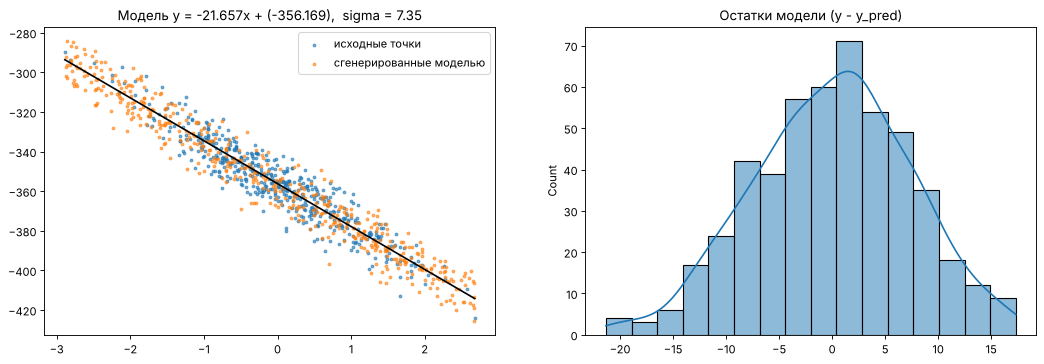

Среднее остатков: -0.0000, стандартное отклонение: 7.345


In [15]:
sigma = np.sqrt(mse(k, b))
rng = np.random.default_rng(14)
X_new = rng.uniform(X.min(), X.max(), size=500)
y_new = k * X_new + b + rng.normal(0, sigma, size=500)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
axes[0].scatter(X, y, s=6, alpha=0.6, label='исходные точки')
axes[0].scatter(X_new, y_new, s=6, alpha=0.6, label='сгенерированные моделью')
axes[0].plot([xmin, xmax], [k * xmin + b, k * xmax + b], color='black')
axes[0].legend()
axes[0].set_title(f'Модель y = {k:.3f}x + ({b:.3f}),  sigma = {sigma:.2f}')

residuals = y - (k * X + b)
sns.histplot(residuals, kde=True, ax=axes[1])
axes[1].set_title('Остатки модели (y - y_pred)')
plt.show()

print(f'Среднее остатков: {residuals.mean():.4f}, стандартное отклонение: {residuals.std():.3f}')

Сгенерированные точки неотличимы от исходных. Остатки распределены симметрично около нуля, систематической ошибки нет. Значит, линейная модель хорошо описывает данные.

**Вывод.** Для распределения из файла `pr13_14.txt` методом градиентного спуска обучена модель линейной регрессии $y = -21.657x - 356.169$ (MSE ≈ 53.95). Результат совпадает с точным решением МНК. Скорость обучения определяет скорость и саму возможность сходимости: при малых $\alpha$ обучение медленное, при $\alpha$ выше ≈ 1.0 - расходится. Начальные значения параметров для выпуклой функции ошибки влияют только на число итераций.

## Контрольные вопросы

**1. Действительно ли алгоритмы могут обучаться? В чем заключается процесс обучения?**

Да, в смысле машинного обучения: алгоритм улучшает качество решения задачи за счёт опыта (данных), а не за счёт явно запрограммированных правил. Программист задаёт только форму модели (здесь - прямую $y = kx + b$) и функцию ошибки. Конкретные значения параметров алгоритм находит сам по примерам.

Процесс обучения - итеративная оптимизация: модель делает прогноз → вычисляется ошибка относительно правильных ответов → параметры корректируются так, чтобы ошибка уменьшилась → цикл повторяется до сходимости. «Знания» модели - это найденные значения параметров (в этой работе $k = -21.657$, $b = -356.169$).

**2. Что такое модель линейной регрессии?**

Линейная регрессия - модель, которая предсказывает числовую величину $y$ как линейную функцию признаков: $\hat y = w_1 x_1 + w_2 x_2 + \ldots + w_m x_m + b$. В случае одного признака - прямая $\hat y = kx + b$, где $k$ - угловой коэффициент (на сколько меняется $y$ при увеличении $x$ на 1), $b$ - свободный член (значение при $x = 0$). Параметры подбираются так, чтобы минимизировать сумму квадратов отклонений прогнозов от реальных значений (метод наименьших квадратов). Решение можно найти аналитически или итеративно - градиентным спуском.

**3. Каким образом производится подбор параметров модели в процессе градиентного спуска?**

1. Параметры инициализируются начальными значениями (например, $k = 0$, $b = 0$).
2. Вычисляются прогнозы $\hat y_i = kx_i + b$ и функция ошибки (MSE).
3. Вычисляется градиент - вектор частных производных ошибки по каждому параметру. Он показывает направление наискорейшего *роста* ошибки.
4. Параметры сдвигаются в противоположную сторону: $\theta \leftarrow \theta - \alpha \nabla MSE(\theta)$.
5. Шаги 2–4 повторяются заданное число итераций или пока ошибка не перестанет заметно уменьшаться.

Чем круче склон функции ошибки, тем больше шаг. Вблизи минимума градиент стремится к нулю, и шаги автоматически уменьшаются.

**4. Что такое темп обучения? Как влияет данный гиперпараметр на процесс обучения?**

Темп (скорость) обучения $\alpha$ - множитель, определяющий величину шага при обновлении параметров. Это *гиперпараметр*: его задаёт человек, алгоритм его не обучает. По результатам эксперимента 1:
* малый $\alpha$ - обучение устойчивое, но медленное, требуется много итераций (при $\alpha = 0.001$ за 200 итераций минимум не достигнут);
* подходящий $\alpha$ - быстрая сходимость (здесь $0.1…0.5$);
* большой $\alpha$ - колебания вокруг минимума ($\alpha = 0.9$);
* слишком большой $\alpha$ - расходимость, ошибка неограниченно растёт ($\alpha = 1.05$; граница для этих данных ≈ 0.998).

**5. Перечислите основные типы диаграмм matplotlib и функции, которые реализуют построение графиков данных типов.**

* линейный график - `plt.plot()` (в работе: прямая модели, кривые ошибки);
* точечная диаграмма - `plt.scatter()` (в работе: исходные точки);
* гистограмма - `plt.hist()`;
* столбчатая диаграмма - `plt.bar()`, `plt.barh()`;
* круговая диаграмма - `plt.pie()`;
* ящик с усами - `plt.boxplot()`;
* линии уровня - `plt.contour()`, `plt.contourf()` (в работе: карта MSE);
* изображения и тепловые карты - `plt.imshow()`, `plt.pcolormesh()`;
* диаграмма с областями - `plt.fill_between()`, `plt.stackplot()`;
* полярные и 3D-графики - `projection='polar'` / `projection='3d'` при создании осей.

Несколько графиков на одной фигуре - `plt.subplots(nrows, ncols)`.

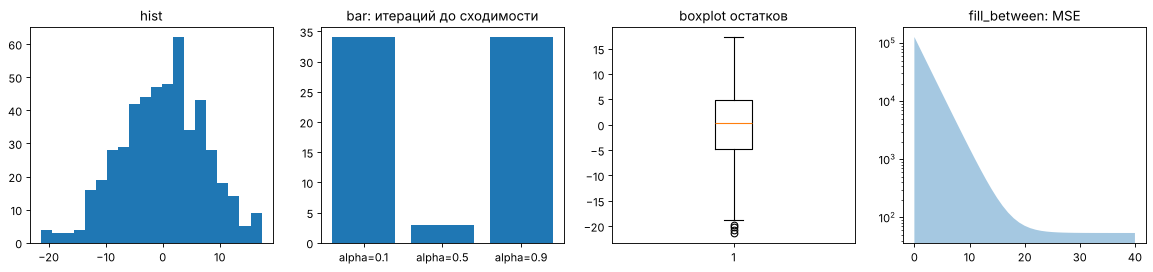

In [16]:
fig, axes = plt.subplots(1, 4, figsize=(18, 3.5))
axes[0].hist(residuals, bins=20)
axes[0].set_title('hist')
axes[1].bar(['alpha=0.1', 'alpha=0.5', 'alpha=0.9'],
            [iterations_to_converge(runs[a]) for a in (0.1, 0.5, 0.9)])
axes[1].set_title('bar: итераций до сходимости')
axes[2].boxplot(residuals)
axes[2].set_title('boxplot остатков')
axes[3].fill_between(np.arange(41), runs[0.1][:41, 2], alpha=0.4)
axes[3].set_yscale('log')
axes[3].set_title('fill_between: MSE')
plt.show()